# Google Play review classification with Naive Bayes

This notebook is the reviewer-facing narrative for the official 4Geeks assignment. The production implementation lives in `train.py`.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

project = Path.cwd().parent
metrics = json.loads((project / 'artifacts/metrics.json').read_text())
metrics

{'dataset': {'rows': 891,
  'duplicates': 1,
  'class_counts': {'0': 584, '1': 307}},
 'splits': {'train': 623, 'validation': 134, 'test': 134},
 'selection': {'validation_winner': 'RandomForest',
  'final_model': 'RandomForest',
  'best_naive_bayes': 'MultinomialNB',
  'best_cross_validation_f1': 0.7184857646469809,
  'best_parameters': {'classifier__alpha': 0.5,
   'vectorizer__min_df': 2,
   'vectorizer__ngram_range': [1, 2]}},
 'test': {'accuracy': 0.8283582089552238,
  'precision': 0.7446808510638298,
  'recall': 0.7608695652173914,
  'f1': 0.7526881720430108,
  'confusion_matrix': [[76, 12], [11, 35]]}}

## Data and leakage controls

The official 891-review dataset is stratified into train, validation, and final test partitions before `CountVectorizer` learns a vocabulary. Every transformer remains inside its scikit-learn pipeline.

In [2]:
comparison = pd.read_csv(project / 'artifacts/validation_model_comparison.csv')
comparison

,model,accuracy,precision,recall,f1
0,RandomForest,0.753731,0.651163,0.608696,0.629213
1,LogisticRegression,0.731343,0.608696,0.608696,0.608696
2,MultinomialNB,0.708955,0.620690,0.391304,0.480000
3,GaussianNB,0.671642,0.527778,0.413043,0.463415
4,BernoulliNB,0.694030,0.666667,0.217391,0.327869


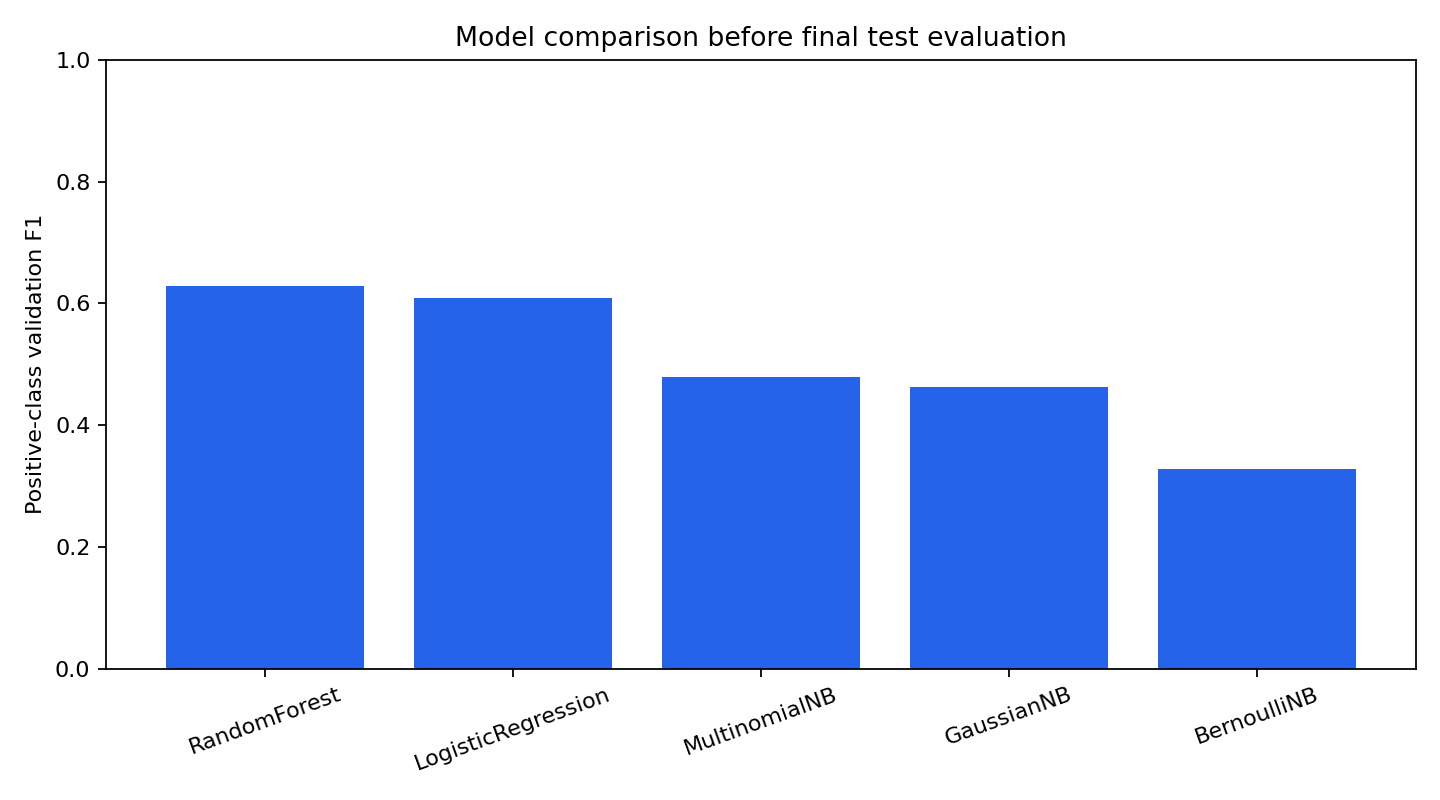

In [3]:
display(Image(filename=project / 'reports/model_comparison.png'))

## Final held-out result

Multinomial Naive Bayes was tuned with five-fold stratified CV. The Random Forest alternative won on validation F1, was refitted on the development partition, and evaluated once on the final test partition.

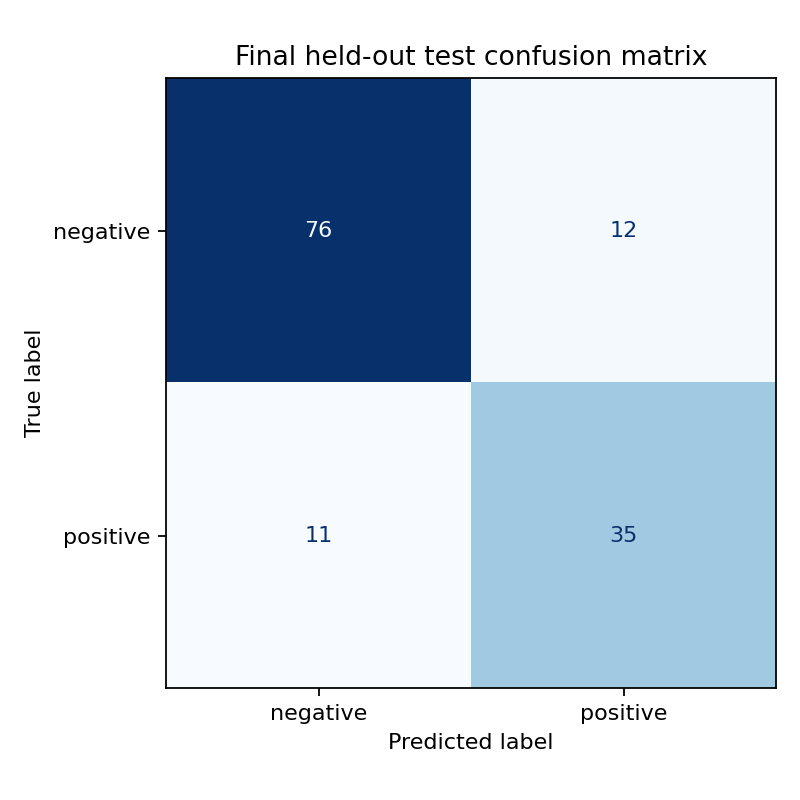

{'accuracy': 0.8283582089552238,
 'precision': 0.7446808510638298,
 'recall': 0.7608695652173914,
 'f1': 0.7526881720430108,
 'confusion_matrix': [[76, 12], [11, 35]]}

In [4]:
display(Image(filename=project / 'reports/test_confusion_matrix.png'))
metrics['test']

## Interpretation

Token counts suit Multinomial Naive Bayes directly. BernoulliNB loses frequency information, while GaussianNB requires a dense matrix and a continuous Gaussian assumption that does not match sparse word counts. Random Forest won the validation comparison and is the final selected pipeline; the tuned Multinomial model is also preserved as the strongest required Naive Bayes implementation and the simpler explainable baseline.

In [5]:
tokens = pd.read_csv(project / 'artifacts/informative_tokens.csv')
tokens.head(12)

,negative_token,negative_log_odds,positive_token,positive_log_odds
0,wechat,-3.327125,birds,4.379488
1,error,-3.090736,angry,4.083222
2,sucks,-3.090736,angry birds,4.083222
3,twitter,-2.997646,excellent,3.934802
4,doesn work,-2.997646,brilliant,3.660365
5,uninstall,-2.947636,hamro,3.549139
6,hangouts,-2.947636,žŕľ ŕľ,3.423976
7,loot,-2.579911,slack,3.423976
8,reinstall,-2.579911,doubt,3.280875
9,update sucks,-2.579911,żŕ ŕľ,3.280875
